In [1]:
# Keep imports and data/output paths relative to the repository root.
import os
import sys
from pathlib import Path
from datetime import datetime
from uuid import uuid4

for repository_dir in (Path.cwd(), *Path.cwd().parents):
    if (repository_dir / ".geofm-root").is_file():
        os.chdir(repository_dir)
        break
else:
    raise FileNotFoundError("Open this notebook from inside the repository.")
if "src" not in sys.path:
    sys.path.insert(0, "src")

EXPERIMENT_NAME = "sen1floods11/croma/upernet_s1"
NOTEBOOK_PATH = "experiments/sen1floods11/croma/upernet_s1/01C_croma_on_sen1floods11_training_UperNet_S1.ipynb"


#### **Imports**

In [2]:
import torch
import torch.nn as nn
import torchvision.transforms.functional as FT
import torch.nn.functional as F
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import csv
import random
import json
import pandas as pd
from IPython.display import display

from PIL import Image
from pathlib import Path
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models.segmentation.fcn import FCNHead
from use_croma import PretrainedCROMA

In [3]:
from croma_upernet_pangaea import (
    load_split_paths, prepare_sample, Sen1Floods11Dataset,
    filter_labeled_training_pairs, random_labeled_crop,
    UPerNetHead, CROMAUPerNet, SCHEMA, PREPROCESSING, PANGAEA_REVISION
)

from segmentation_metrics import (binary_metrics, confusion_counts, METRIC_KEYS,
    metric_table, save_per_chip_metrics, clean_json, plot_metric_history)

from sar_input_quality import audit_sar_pairs


#### **First things first**


In [4]:
SEED = 234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

pretrained_path = "pretrained/croma/CROMA_large.pt"

path_to_the_dataset = "datasets/sen1floods11/sen1floods11_hand_labeled_only/HandLabeled/"

path_to_the_dataset_index = "datasets/sen1floods11/sen1floods11_hand_labeled_only/flood_handlabeled/"

path_to_X = path_to_the_dataset + "S1Hand/"

path_to_Y = path_to_the_dataset + "LabelHand/"

path_to_train_csv = path_to_the_dataset_index + "flood_train_data.csv"

path_to_val_csv = path_to_the_dataset_index + "flood_valid_data.csv"

path_to_test_csv = path_to_the_dataset_index + "flood_test_data.csv"
path_to_test_bolivia_csv = path_to_the_dataset_index + "flood_bolivia_data.csv"

print(device)

cuda


In [5]:
CROP_SIZE = 120
IGNORE_INDEX = 255  # Equivalent to PANGAEA's -1 after remapping the same ignored pixels.
BATCH_SIZE = 8  # Real batch of 8: accumulation does not reproduce BatchNorm statistics.
TILE_BATCH_SIZE = 8


#### **Functions**

In [6]:
def preprocess_train(data):
    # Reject crops without supervision; valid land-only crops remain eligible.
    return prepare_sample(random_labeled_crop(*data, crop_size=CROP_SIZE))


def preprocess_eval(data):
    return prepare_sample(data)


#### Creating datasets

In [7]:
train_data = load_split_paths(path_to_train_csv, path_to_X, path_to_Y)
val_data = load_split_paths(path_to_val_csv, path_to_X, path_to_Y)
# Audit raw SAR before NaN filling; do not delete source files.
train_input_audit = audit_sar_pairs(train_data)
val_input_audit = audit_sar_pairs(val_data)
excluded_missing_sar_train = [pair for pair, bad in zip(train_data, train_input_audit.exclude_missing_sar) if bad]
train_data = [pair for pair, bad in zip(train_data, train_input_audit.exclude_missing_sar) if not bad]
print(f"Excluded training images without usable SAR: {len(excluded_missing_sar_train)}")
display(train_input_audit[train_input_audit.exclude_missing_sar])
# Filter the in-memory training list; preserve original files and evaluation splits.
train_data, excluded_unlabeled_train = filter_labeled_training_pairs(train_data)
print(f"Excluded fully ignored training images: {len(excluded_unlabeled_train)}")


Excluded training images without usable SAR: 0


,chip_id,image_path,label_path,sar_usable_pixels,sar_usable_fraction,valid_label_pixels,labeled_usable_sar_pixels,exclude_missing_sar


Excluded fully ignored training images: 1


In [8]:
print(f"Train samples: {len(train_data)}")
print(f"Validation samples: {len(val_data)}")

Train samples: 251
Validation samples: 89


In [9]:
print(train_data[0])

(WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/S1Hand/Ghana_103272_S1Hand.tif'), WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/LabelHand/Ghana_103272_LabelHand.tif'))


In [10]:
train_dataset = Sen1Floods11Dataset(
    data_list=train_data,
    preprocess_func=preprocess_train
)

valid_dataset = Sen1Floods11Dataset(
    data_list=val_data,
    preprocess_func=preprocess_eval
)

#### Creating DataLoaders

In [11]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=torch.utils.data.DistributedSampler(train_dataset, num_replicas=1, rank=0),
    generator=torch.Generator().manual_seed(SEED),
    drop_last=True,
    num_workers=0,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Training batch checks

images, masks = next(iter(train_loader))

print("Training images:", images.shape)
print("Training masks:", masks.shape)

print("Image min:", images.min().item())
print("Image max:", images.max().item())

print("Water pixels:", (masks == 1).sum().item())
print("Non-water pixels:", (masks == 0).sum().item())
print("Ignored pixels:", (masks == IGNORE_INDEX).sum().item())

assert torch.isfinite(images).all()

assert set(torch.unique(masks).tolist()).issubset(
    {0, 1, IGNORE_INDEX}
)

# Validation batch checks

val_images, val_masks = next(iter(valid_loader))

print("-" * 40)
print("Validation images:", val_images.shape)
print("Validation masks:", val_masks.shape)

Training images: torch.Size([8, 2, 120, 120])
Training masks: torch.Size([8, 120, 120])
Image min: -6.036761283874512
Image max: 5.360342025756836
Water pixels: 5494
Non-water pixels: 104995
Ignored pixels: 4711
----------------------------------------
Validation images: torch.Size([1, 2, 512, 512])
Validation masks: torch.Size([1, 512, 512])


##### Loading CROMA

In [12]:
croma = PretrainedCROMA(pretrained_path= pretrained_path, 
                        size='large', 
                        modality='SAR', 
                        image_resolution=120)

croma = croma.to(device)

Initializing SAR encoder


In [13]:
croma.requires_grad_(False) # Freeze the weights of CROMA
croma.eval()

PretrainedCROMA(
  (s1_encoder): ViT(
    (linear_input): Linear(in_features=128, out_features=1024, bias=True)
    (transformer): BaseTransformer(
      (layers): ModuleList(
        (0-11): 12 x ModuleList(
          (0): Attention(
            (to_qkv): Linear(in_features=1024, out_features=3072, bias=False)
            (to_out): Linear(in_features=1024, out_features=1024, bias=True)
            (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=0.0, inplace=False)
          )
          (1): FFN(
            (net): Sequential(
              (0): Linear(in_features=1024, out_features=4096, bias=True)
              (1): GELU(approximate='none')
              (2): Dropout(p=0.0, inplace=False)
              (3): Linear(in_features=4096, out_features=1024, bias=True)
            )
            (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
          )
        )
      )
      (norm_out): LayerNo

### Creating the head

In [14]:
# PANGAEA croma_sar.yaml uses zero-based indices 3, 5, 7, 11.
OUT_INDICES = (3, 5, 7, 11)


In [15]:
# Full 1024-channel feature pyramid; 512-channel UPerNet decoder.
# BatchNorm2d is the single-process equivalent of upstream SyncBatchNorm.
HEAD_CONFIG = dict(in_channels=1024, channels=512, num_classes=2,
                   out_indices=list(OUT_INDICES), pool_scales=[1, 2, 3, 6])


In [ ]:
head = UPerNetHead(**HEAD_CONFIG).to(device)

In [ ]:
model = CROMAUPerNet(croma, head).to(device)

In [18]:
EPOCHS = 80
EVAL_INTERVAL = 2
LR = 1e-4
WEIGHT_DECAY = 0.05
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
optimizer = torch.optim.AdamW(model.head.parameters(), lr=LR,
                              betas=(0.9, 0.999), weight_decay=WEIGHT_DECAY)
# PANGAEA steps the scheduler after every optimizer update.
TOTAL_STEPS = len(train_loader) * EPOCHS
LR_MILESTONES = [int(TOTAL_STEPS * fraction) for fraction in (0.6, 0.9)]
scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer, milestones=LR_MILESTONES, gamma=0.1
)


In [ ]:
def train_one_epoch(model, train_loader, optimizer, criterion, device):
    
    model.train()
    total_loss = 0.0
    total_valid_pixels = 0
    
    counts = np.zeros(4, dtype=np.int64)
    
    for images, masks in train_loader:
        
        images = images.to(device)
        masks = masks.to(device)
        
        valid_pixels = (masks != IGNORE_INDEX).sum().item()
        
        if not valid_pixels:
            raise RuntimeError("Entire batch is unlabeled; inspect sampling before continuing.")
        
        optimizer.zero_grad(set_to_none=True)
        
        logits = model(images)
        
        loss = criterion(logits, masks)
        
        counts += confusion_counts(logits.detach().argmax(1).cpu().numpy(), masks.cpu().numpy())
        
        if not torch.isfinite(loss):
            raise FloatingPointError("Nonfinite training loss.")
        
        loss.backward()
        optimizer.step()
        scheduler.step()
        
        total_loss += loss.item() * valid_pixels
        total_valid_pixels += valid_pixels
        
    if not total_valid_pixels:
        raise RuntimeError("No valid training pixels.")
    # These metrics describe sampled training crops, not full-image training evaluation.
    train_one_epoch.last_metrics = binary_metrics(*counts)
    return total_loss / total_valid_pixels


In [20]:
@torch.inference_mode()
def sliding_window_logits(
    model,
    image,
    device,
    tile_size=120,
    stride=None,
    tile_batch_size=TILE_BATCH_SIZE
):
    """
    Predict segmentation logits for one complete image.

    Parameters
    ----------
    model:
        Frozen CROMA + trained UPerNet head.

    image:
        Tensor [2, H, W], already normalized.

    device:
        CUDA or CPU.

    tile_size:
        Spatial size of each CROMA input (120).

    stride:
        None uses the PANGAEA evenly spaced sliding-window grid.

    tile_batch_size:
        Number of windows processed simultaneously.

    Returns
    -------
    logits:
        Tensor [2, H, W] on CPU.
    """

    model.eval()

    C, H, W = image.shape

    assert C == 2
    assert H >= tile_size and W >= tile_size
    assert stride is None or 0 < stride <= tile_size

    # Generate starting positions along one dimension
    def get_starts(length):
        import math
        # Upstream default: 5 evenly spaced windows per axis for 512px / 120px.
        count = math.ceil(length / tile_size) if stride is None else math.ceil((length - tile_size) / stride) + 1
        return torch.linspace(0, length - tile_size, count).round().long().tolist()

    # All window coordinates
    positions = [
        (top, left)
        for top in get_starts(H)
        for left in get_starts(W)
    ]

    # Accumulate predictions and coverage counts
    logits_sum = torch.zeros((2, H, W), dtype=torch.float32)
    counts = torch.zeros((H, W), dtype=torch.float32)

    # Process windows in batches
    for start in range(0, len(positions), tile_batch_size):

        batch_positions = positions[start:start + tile_batch_size]

        # Extract tiles
        tiles = torch.stack([
            image[:, top:top + tile_size, left:left + tile_size]
            for top, left in batch_positions
        ])

        tiles = tiles.to(device)

        # Run frozen CROMA + UPerNet head
        outputs = model(tiles).cpu()

        # Place tile predictions back into the full image
        for (top, left), logits in zip(batch_positions, outputs):

            logits_sum[
                :, top:top + tile_size, left:left + tile_size
            ] += logits

            counts[
                top:top + tile_size, left:left + tile_size
            ] += 1

    assert (counts > 0).all(), "Some pixels were not covered."

    # Average logits wherever windows overlap
    return logits_sum / counts.unsqueeze(0)


import torch.nn.functional as F

@torch.inference_mode()
def validate(model, valid_loader, criterion, device):

    model.eval()

    total_loss = 0.0
    total_valid_pixels = 0

    TP = FP = FN = TN = 0

    for images, masks in valid_loader:

        # Process every complete image in the batch.
        for image, mask in zip(images, masks):
            mask = mask.cpu()
            
            
            valid = mask != IGNORE_INDEX

            if not valid.any():
                continue

            # Reconstruct logits using overlapping windows.
            logits = sliding_window_logits(
                model,
                image,
                device,
                tile_size=CROP_SIZE,
                stride=None,
                tile_batch_size=TILE_BATCH_SIZE
            )
            
            logits_device = logits.unsqueeze(0).to(device)
            mask_device = mask.unsqueeze(0).to(device=device, dtype=torch.long)

            loss = criterion(logits_device, mask_device)

            image_valid_pixels = valid.sum().item()

            total_loss += loss.item() * image_valid_pixels
            total_valid_pixels += image_valid_pixels

            prediction = logits.argmax(dim=0)

            TP += ((prediction == 1) & (mask == 1) & valid).sum().item()
            FP += ((prediction == 1) & (mask == 0) & valid).sum().item()
            FN += ((prediction == 0) & (mask == 1) & valid).sum().item()
            TN += ((prediction == 0) & (mask == 0) & valid).sum().item()

    if total_valid_pixels == 0:
        raise RuntimeError("No valid validation pixels.")

    val_loss = total_loss / total_valid_pixels

    return {"val_loss": val_loss, **binary_metrics(TP, FP, FN, TN)}


In [21]:
metrics = validate(model, valid_loader, criterion, device)
display(metric_table({"validation_baseline": metrics}).T)


split,validation_baseline
val_loss,6.326416e-01
accuracy,8.945184e-01
water_iou,8.182081e-02
nonwater_iou,8.935175e-01
miou,4.876691e-01
precision,6.701845e-01
recall,8.525365e-02
f1,1.512650e-01
omission_error,9.147463e-01
commission_error,3.298155e-01


In [22]:
model_name = "croma_large_upernet_pangaea_sar.pt"
run_id = datetime.now().astimezone().strftime("%Y-%m-%d_%H-%M-%S_%f") + "_" + uuid4().hex[:8]
checkpoint_dir = Path("runs") / EXPERIMENT_NAME / f"train_{Path(model_name).stem}_{run_id}"
checkpoint_dir.mkdir(parents=True, exist_ok=False)
checkpoint_path = checkpoint_dir / model_name
history_path = checkpoint_dir / "croma_training_history.json"

print(f"Run directory: {checkpoint_dir}")
train_input_audit.to_csv(checkpoint_dir / "training_input_quality.csv", index=False)
val_input_audit.to_csv(checkpoint_dir / "validation_input_quality.csv", index=False)

run_config = {
    "experiment": EXPERIMENT_NAME, "model_name": checkpoint_path.stem,
    "phase": "train", "run_id": run_id,
    "started_at": datetime.now().astimezone().isoformat(),
    "notebook": NOTEBOOK_PATH, "schema": SCHEMA,
    "pangaea_revision": PANGAEA_REVISION, "modality": "SAR",
    "pretrained_weights": pretrained_path, "head_config": HEAD_CONFIG,
    "preprocessing": PREPROCESSING, "crop_size": CROP_SIZE,
    "epochs": EPOCHS, "eval_interval": EVAL_INTERVAL, "seed": SEED,
    "batch_size": BATCH_SIZE, "drop_last": True, "precision": "fp32",
    "backbone_frozen": True, "loss": "unweighted_cross_entropy",
    "ignore_index": IGNORE_INDEX, "optimizer": "AdamW",
    "learning_rate": LR, "weight_decay": WEIGHT_DECAY,
    "scheduler": {"name": "MultiStepLR", "milestones": LR_MILESTONES,
                  "gamma": 0.1, "step_unit": "optimizer_update"},
    "checkpoint_selection": "validation_miou",
    "training_sampling": {"exclude_fully_ignored_images": True,
                          "reject_fully_ignored_crops": True,
                          "max_crop_attempts": 32,
                          "fallback": "random_crop_containing_random_valid_pixel",
                          "water_oversampling": False,
                          "exclude_images_without_usable_sar": True},
    "excluded_missing_sar_training_images": [str(pair[0]) for pair in excluded_missing_sar_train],
    "excluded_unlabeled_training_images": [str(pair[0]) for pair in excluded_unlabeled_train],
    "inference_grid": "linspace_ceil_image_div_tile",
    "runtime_adaptations": ["single_process_BatchNorm2d", "num_workers_0", "ignore_label_255"],
    "checkpoint": checkpoint_path.as_posix(), "history": history_path.as_posix(),
}

with (checkpoint_dir / "run.json").open("w", encoding="utf-8") as f:
    json.dump(run_config, f, indent=4)

# Include the untrained validation baseline, as PANGAEA evaluates at epoch zero.
best_val_miou = metrics["miou"]
best_val_iou = metrics["water_iou"]
best_epoch = 0

def save_best(epoch, current_metrics):
    torch.save({
        "schema": SCHEMA, "pangaea_revision": PANGAEA_REVISION,
        "head_config": HEAD_CONFIG, "preprocessing": PREPROCESSING,
        "crop_size": CROP_SIZE, "pretrained_weights": pretrained_path,
        "epoch": epoch, "head_state_dict": model.head.state_dict(),
        "best_val_miou": current_metrics["miou"],
        "best_val_water_iou": current_metrics["water_iou"],
        "val_miou": current_metrics["miou"], "val_loss": current_metrics["val_loss"],
        "seed": SEED, "run_config": run_config,
        "validation_metrics": clean_json(current_metrics),
    }, checkpoint_path)

save_best(0, metrics)
history = {key: [] for key in ("train_loss", "val_loss", "val_water_iou", "val_miou", "learning_rate")}
baseline_metrics = dict(metrics)
for key in METRIC_KEYS:
    history.setdefault("val_" + key, [])
    history.setdefault("train_" + key, [])
validation_rows = [{"epoch": 0, **metrics}]
pd.DataFrame(validation_rows).to_csv(checkpoint_dir / "validation_metrics.csv", index=False)


for epoch in range(EPOCHS):

    train_loader.sampler.set_epoch(epoch)
    epoch_lr = optimizer.param_groups[0]["lr"]

    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)


    evaluate_now = (epoch + 1) % EVAL_INTERVAL == 0 or epoch + 1 == EPOCHS
    metrics = validate(model, valid_loader, criterion, device) if evaluate_now else None


    history["train_loss"].append(train_loss)
    train_metrics = getattr(train_one_epoch, "last_metrics", {})

    for key in METRIC_KEYS:
        history["train_" + key].append(train_metrics.get(key))
        if key not in ("water_iou", "miou"):
            history["val_" + key].append(metrics.get(key) if metrics is not None else None)

    if metrics is not None:
        validation_rows.append({"epoch": epoch + 1, **metrics})
        pd.DataFrame(validation_rows).to_csv(checkpoint_dir / "validation_metrics.csv", index=False)
        display(metric_table({f"validation_epoch_{epoch+1}": metrics}).T)

    history["learning_rate"].append(epoch_lr)

    for key, metric in (("val_loss", "val_loss"), ("val_water_iou", "water_iou"), ("val_miou", "miou")):
        history[key].append(metrics[metric] if metrics is not None else None)

    if metrics is not None and metrics["miou"] > best_val_miou:
        best_val_miou = metrics["miou"]
        best_val_iou = metrics["water_iou"]
        best_epoch = epoch + 1
        save_best(best_epoch, metrics)

    with history_path.open("w", encoding="utf-8") as f:
        json.dump(clean_json({"epochs_completed": epoch + 1, "best_epoch": best_epoch,
                   "best_val_miou": best_val_miou, "best_val_water_iou": best_val_iou,
                   "baseline_metrics": baseline_metrics, "history": history}), f, indent=4, allow_nan=False)
    message = f"Epoch [{epoch+1:02d}/{EPOCHS}] | LR: {epoch_lr:.2e} | Train Loss: {train_loss:.4f}"

    if metrics is not None:
        message += (f" | Val Loss: {metrics['val_loss']:.4f}"
                    f" | Water IoU: {metrics['water_iou']:.4f} | mIoU: {metrics['miou']:.4f}")
    pd.DataFrame(history).rename_axis("epoch_index").to_csv(checkpoint_dir / "all_metrics_history.csv")
    print(message)

print(f"Best checkpoint: epoch {best_epoch}, mIoU {best_val_miou:.4f}, water IoU {best_val_iou:.4f}")


Run directory: runs\croma_sen1floods11\UperNet_head\train_croma_large_upernet_pangaea_sar_2026-10-22_16-00-47_446450_95299899
Epoch [01/80] | LR: 1.00e-04 | Train Loss: 0.4504


split,validation_epoch_2
val_loss,1.984030e-01
accuracy,9.231896e-01
water_iou,3.215023e-01
nonwater_iou,9.202885e-01
miou,6.208954e-01
precision,9.250006e-01
recall,3.301074e-01
f1,4.865710e-01
omission_error,6.698926e-01
commission_error,7.499937e-02


Epoch [02/80] | LR: 1.00e-04 | Train Loss: 0.2130 | Val Loss: 0.1984 | Water IoU: 0.3215 | mIoU: 0.6209
Epoch [03/80] | LR: 1.00e-04 | Train Loss: 0.2109


split,validation_epoch_4
val_loss,1.433368e-01
accuracy,9.464588e-01
water_iou,5.622160e-01
nonwater_iou,9.425055e-01
miou,7.523608e-01
precision,8.509361e-01
recall,6.236360e-01
f1,7.197673e-01
omission_error,3.763640e-01
commission_error,1.490639e-01


Epoch [04/80] | LR: 1.00e-04 | Train Loss: 0.1862 | Val Loss: 0.1433 | Water IoU: 0.5622 | mIoU: 0.7524
Epoch [05/80] | LR: 1.00e-04 | Train Loss: 0.1596


split,validation_epoch_6
val_loss,1.478668e-01
accuracy,9.468267e-01
water_iou,5.778751e-01
nonwater_iou,9.426522e-01
miou,7.602637e-01
precision,8.224886e-01
recall,6.602162e-01
f1,7.324725e-01
omission_error,3.397838e-01
commission_error,1.775114e-01


... (71 outputs left out)

split,validation_epoch_78
val_loss,1.166581e-01
accuracy,9.543914e-01
water_iou,6.222464e-01
nonwater_iou,9.506865e-01
miou,7.864665e-01
precision,8.775711e-01
recall,6.813977e-01
f1,7.671416e-01
omission_error,3.186023e-01
commission_error,1.224289e-01


Epoch [78/80] | LR: 1.00e-06 | Train Loss: 0.1252 | Val Loss: 0.1167 | Water IoU: 0.6222 | mIoU: 0.7865
Epoch [79/80] | LR: 1.00e-06 | Train Loss: 0.1057


split,validation_epoch_80
val_loss,1.164665e-01
accuracy,9.543801e-01
water_iou,6.212833e-01
nonwater_iou,9.506898e-01
miou,7.859865e-01
precision,8.800178e-01
recall,6.787802e-01
f1,7.664093e-01
omission_error,3.212198e-01
commission_error,1.199822e-01


Epoch [80/80] | LR: 1.00e-06 | Train Loss: 0.1190 | Val Loss: 0.1165 | Water IoU: 0.6213 | mIoU: 0.7860
Best checkpoint: epoch 68, mIoU 0.7985, water IoU 0.6451


In [23]:
print(
    "CROMA trainable parameters:",
    sum(p.numel() for p in model.croma.parameters()
        if p.requires_grad)
)

print(
    "Head trainable parameters:",
    sum(p.numel() for p in model.head.parameters()
        if p.requires_grad)
)

CROMA trainable parameters: 0
Head trainable parameters: 46948354


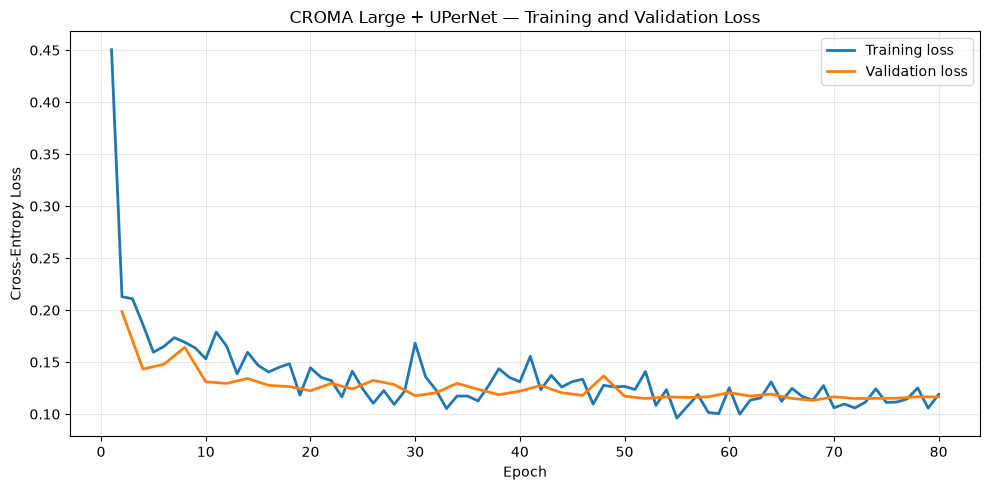

In [24]:
epochs = range(1, len(history["train_loss"]) + 1)
eval_epochs = [i + 1 for i, value in enumerate(history["val_loss"]) if value is not None]

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["train_loss"],
    label="Training loss",
    linewidth=2
)

plt.plot(
    eval_epochs,
    [value for value in history["val_loss"] if value is not None],
    label="Validation loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("CROMA Large + UPerNet — Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(checkpoint_dir / "training_loss.png", dpi=150, bbox_inches="tight")
plt.show()

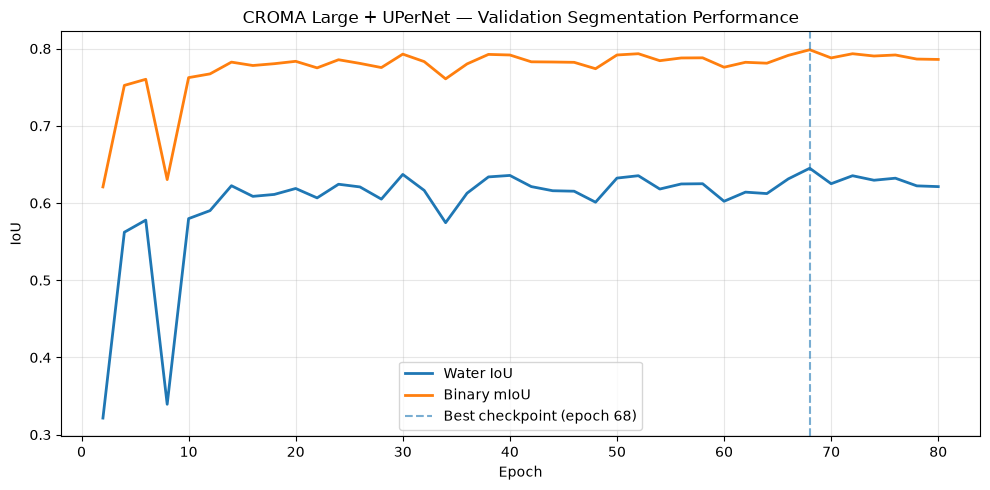

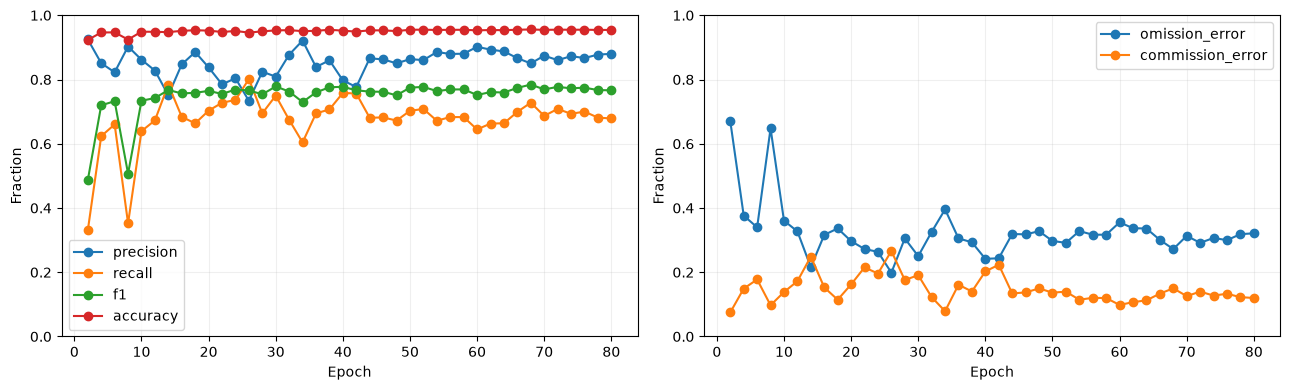

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(
    eval_epochs,
    [value for value in history["val_water_iou"] if value is not None],
    label="Water IoU",
    linewidth=2
)

plt.plot(
    eval_epochs,
    [value for value in history["val_miou"] if value is not None],
    label="Binary mIoU",
    linewidth=2
)

plt.axvline(
    best_epoch,
    linestyle="--",
    alpha=0.6,
    label=f"Best checkpoint (epoch {best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.title("CROMA Large + UPerNet — Validation Segmentation Performance")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(checkpoint_dir / "validation_iou.png", dpi=150, bbox_inches="tight")
plt.show()
plot_metric_history(history, checkpoint_dir)
plt.show()
